# Task 1 – First Look at the Chicago Food Inspections Data
**How to get the file:** open the Chicago Data Portal page "Food Inspections", click **Export → CSV**, and save it as `Food_Inspections.csv`.
In Colab, put it in Google Drive (it is large) and run the next cell to connect Drive. Change the path if you saved it somewhere else.

At the end, write your **5 observations** in the last cell, to discuss together.

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [70]:
# connect Google Drive (only needed in Colab)
from google.colab import drive
drive.mount('/content/drive')

ModuleNotFoundError: No module named 'google'

In [ ]:
# change the path to where you saved the file
food = pd.read_csv('/content/drive/MyDrive/Food_Inspections.csv')
food.head()

In [ ]:
#since I imported the dataset into the working directory Im using this
food = pd.read_csv('Food_Inspections.csv') #data from 1 Jan 2010 till 17 Oct 2026

## 1. Size, columns and types

In [ ]:
food.shape

(317175, 17)

In [ ]:
food.columns

Index(['Inspection ID', 'DBA Name', 'AKA Name', 'License #', 'Facility Type',
       'Risk', 'Address', 'City', 'State', 'Zip', 'Inspection Date',
       'Inspection Type', 'Results', 'Violations', 'Latitude', 'Longitude',
       'Location'],
      dtype='str')

In [ ]:
food.info()

<class 'pandas.DataFrame'>
RangeIndex: 317175 entries, 0 to 317174
Data columns (total 17 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Inspection ID    317175 non-null  int64  
 1   DBA Name         317175 non-null  str    
 2   AKA Name         314751 non-null  str    
 3   License #        317156 non-null  float64
 4   Facility Type    311818 non-null  str    
 5   Risk             317088 non-null  str    
 6   Address          317175 non-null  str    
 7   City             316993 non-null  str    
 8   State            317099 non-null  str    
 9   Zip              317133 non-null  float64
 10  Inspection Date  317175 non-null  str    
 11  Inspection Type  317174 non-null  str    
 12  Results          317175 non-null  str    
 13  Violations       227682 non-null  str    
 14  Latitude         316113 non-null  float64
 15  Longitude        316113 non-null  float64
 16  Location         316113 non-null  str    
dtypes:

In [ ]:
food.describe()

,Inspection ID,License #,Zip,Latitude,Longitude
count,3.171750e+05,3.171560e+05,317133.000000,316113.000000,316113.000000
mean,1.868536e+06,1.807529e+06,60628.793232,41.880563,-87.676373
std,7.351689e+05,9.494890e+05,199.934815,0.080860,0.058435
min,4.424700e+04,0.000000e+00,10014.000000,41.644670,-87.906874
25%,1.375654e+06,1.472957e+06,60614.000000,41.831831,-87.707373
50%,2.088877e+06,2.103360e+06,60625.000000,41.891728,-87.666350
75%,2.559286e+06,2.463316e+06,60643.000000,41.939475,-87.634874
max,2.645351e+06,9.999999e+06,91706.000000,42.021064,-87.525094


In [ ]:
# missing values in each column
food.isnull().sum()

Inspection ID          0
DBA Name               0
AKA Name            2424
License #             19
Facility Type       5357
Risk                  87
Address                0
City                 182
State                 76
Zip                   42
Inspection Date        0
Inspection Type        1
Results                0
Violations         89493
Latitude            1062
Longitude           1062
Location            1062
dtype: int64

In [ ]:
food.head()

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location
0,2645329,LA MICHOACANA,LA MICHOACANA,3104395.0,Restaurant,Risk 1 (High),2740 W 59TH ST,CHICAGO,IL,60629.0,10/16/2026,License,Pass,58. ALLERGEN TRAINING AS REQUIRED - Comments: ...,41.786531,-87.692777,"(41.786530774401776, -87.69277691398389)"
1,2645351,IRON CAFE,IRON CAFE,2993280.0,Restaurant,Risk 2 (Medium),3700 S IRON ST,CHICAGO,IL,60609.0,10/16/2026,License,Fail,10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLI...,41.826881,-87.659475,"(41.82688091287133, -87.65947456175756)"
2,2645334,Dewey,Dewey,22951.0,School,Risk 1 (High),5415 S Union(700W) AVE,CHICAGO,IL,60609.0,10/16/2026,Canvass,Pass,NaN,NaN,NaN,NaN
3,2645326,MICHOACANA SWEETS,MICHOACANA SWEETS,2961261.0,Restaurant,Risk 2 (Medium),2740 W 59TH ST,CHICAGO,IL,60629.0,10/16/2026,Canvass,Out of Business,NaN,41.786531,-87.692777,"(41.786530774401776, -87.69277691398389)"
4,2645333,Stepping Stones Nursery School,Stepping Stones Nursery School,3016043.0,Children's Services Facility,Risk 1 (High),2750 W LAWRENCE AVE,CHICAGO,IL,60625.0,10/16/2026,License Re-Inspection,Pass,NaN,41.968645,-87.698217,"(41.96864515206485, -87.69821695287187)"


## 2. What values do the main columns have?

In [ ]:
# all the different results (we will keep only Pass, Pass w/ Conditions, Fail)
food['Results'].value_counts()

Results
Pass                    164200
Fail                     61081
Pass w/ Conditions       47005
Out of Business          25941
No Entry                 14215
Not Ready                 4637
Business Not Located        96
Name: count, dtype: int64

In [ ]:
food['Risk'].value_counts()

Risk
Risk 1 (High)      236126
Risk 2 (Medium)     56262
Risk 3 (Low)        24610
All                    90
Name: count, dtype: int64

In [ ]:
# 15 most common facility types
food['Facility Type'].value_counts().head(15)

Facility Type
Restaurant                         215179
Grocery Store                       38007
School                              19849
Children's Services Facility         7813
Bakery                               4560
Daycare Above and Under 2 Years      4206
Daycare (2 - 6 Years)                3266
Long Term Care                       2438
Catering                             1960
Liquor                               1372
Mobile Food Preparer                 1324
Hospital                              987
Mobile Food Dispenser                 967
Golden Diner                          894
Daycare Combo 1586                    627
Name: count, dtype: int64

In [ ]:
# 15 most common inspection types
food['Inspection Type'].value_counts().head(15)

Inspection Type
Canvass                     163664
License                      42569
Canvass Re-Inspection        35320
Complaint                    30106
License Re-Inspection        12868
Complaint Re-Inspection      12647
Short Form Complaint          9346
Non-Inspection                5744
Suspected Food Poisoning      1028
Consultation                   679
License-Task Force             604
Tag Removal                    603
Recent Inspection              544
Out of Business                284
Task Force Liquor 1475         252
Name: count, dtype: int64

## 3. Dates: how many inspections per year?

In [ ]:
# turn the date text (MM/DD/YYYY) into a real date, then take the year
# (pd.to_datetime is new for us: it is the standard pandas way to read dates)
food['Inspection Date'] = pd.to_datetime(food['Inspection Date'])
food['Year'] = food['Inspection Date'].dt.year
food['Year'].value_counts().sort_index()

Year
2010    18068
2011    18747
2012    18866
2013    20947
2014    21540
2015    20911
2016    22818
2017    21587
2018    17192
2019    19052
2020    15123
2021    15868
2022    16936
2023    18261
2024    19228
2025    19205
2026    12826
Name: count, dtype: int64

In [ ]:
food[(food['Inspection Date'] >= '2018-07-')]

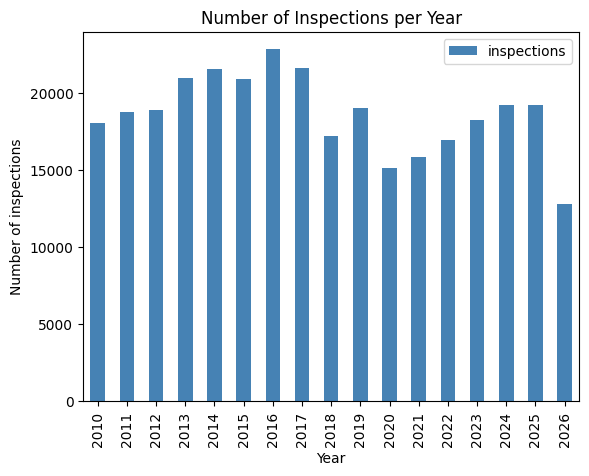

In [ ]:
food['Year'].value_counts().sort_index().plot.bar(color='steelblue', label='inspections')
plt.title('Number of Inspections per Year')
plt.xlabel('Year')
plt.ylabel('Number of inspections')
plt.legend()
plt.show()

In [ ]:
food[food['Results'] == 'Out of Business'].groupby('Year')['Results'].count()

Year
2010     676
2011    1147
2012    2592
2013    3167
2014    2150
2015    1879
2016    1546
2017    1504
2018    1193
2019    1443
2020    1399
2021    1246
2022    1278
2023    1305
2024    1437
2025    1284
2026     695
Name: Results, dtype: int64

## 4. Do the results change over the years? (first sign of the 2018 change)

In [ ]:
# keep only real inspection results
real = food[food['Results'].isin(['Pass', 'Pass w/ Conditions', 'Fail'])]
print('Rows before:', len(food), ' Rows with a real result:', len(real))

Rows before: 317175  Rows with a real result: 272286


In [ ]:
# share of each result in each year (each row adds up to 1)
ct = pd.crosstab(real['Year'], real['Results'])
year_share = ct.divide(ct.sum(axis='columns'), axis='rows')
year_share

Results,Fail,Pass,Pass w/ Conditions
Year,,,
2010,0.259061,0.658958,0.081981
2011,0.247668,0.666117,0.086215
2012,0.227369,0.677051,0.095580
2013,0.196215,0.700961,0.102824
2014,0.199721,0.676279,0.124000
2015,0.201598,0.677789,0.120613
2016,0.216415,0.650957,0.132628
2017,0.222769,0.661603,0.115628
2018,0.223449,0.429052,0.347498


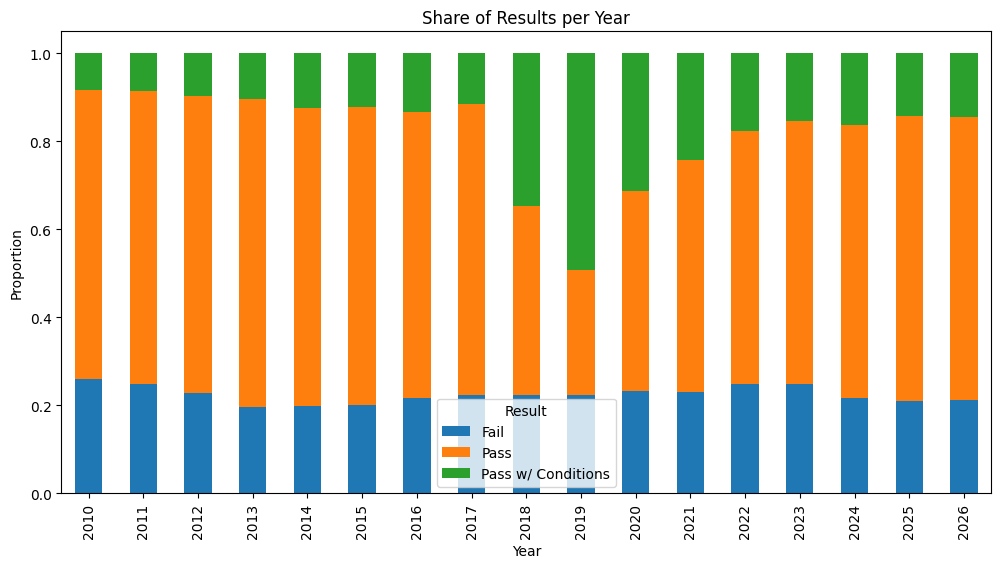

In [ ]:
year_share.plot.bar(stacked=True, figsize=(12, 6))
plt.title('Share of Results per Year')
plt.xlabel('Year')
plt.ylabel('Proportion')
plt.legend(title='Result')
plt.show()

## 5. Periods: before, transition, after the July 2018 change

In [ ]:
def get_period(date):
    if date < pd.Timestamp('2018-07-01'):
        return 'Pre'
    elif date < pd.Timestamp('2019-07-01'):
        return 'Transition'
    else:
        return 'Post'

real = real.copy()
real['Period'] = real['Inspection Date'].apply(get_period)
real['Period'].value_counts()

Period
Pre           151220
Post          106307
Transition     14759
Name: count, dtype: int64

In [ ]:
ct_period = pd.crosstab(real['Period'], real['Results'])
ct_period.divide(ct_period.sum(axis='columns'), axis='rows')

Results,Fail,Pass,Pass w/ Conditions
Period,,,
Post,0.229769,0.563359,0.206873
Pre,0.221756,0.669019,0.109225
Transition,0.211464,0.212887,0.575649


## 6. Violations text

In [ ]:
# look at one full violations text to see its format
print(real['Violations'].dropna().iloc[0])

58. ALLERGEN TRAINING AS REQUIRED - Comments: OBSERVED NO ALLERGEN TRAINING CERTIFICATE ON SITE FOR CERTIFIED MANAGER. INSTRUCTED PERSON IN CHARGE TO OBTAIN CERTIFICATE AND MAINTAIN ON SITE.


In [ ]:
# one violation before and one after the change, to compare the numbering
print('BEFORE:', real[real['Period'] == 'Pre']['Violations'].dropna().iloc[0][:300])
print()
print('AFTER :', real[real['Period'] == 'Post']['Violations'].dropna().iloc[0][:300])

BEFORE: 32. FOOD AND NON-FOOD CONTACT SURFACES PROPERLY DESIGNED, CONSTRUCTED AND MAINTAINED - Comments: RUBBER  GASKET ON THE DOOR OF ONE OF THE CHEST FREEZER IN THE KITCHEN FIRST FLOOR WORN OUT/RIPPED OFF. MUST REPAIR/REPLACE AND MAINTAIN.  BOTH CHEST FREEZER IN THE KITCHEN FIRST FLOOR WITH HEAVY ICE ACCU

AFTER : 58. ALLERGEN TRAINING AS REQUIRED - Comments: OBSERVED NO ALLERGEN TRAINING CERTIFICATE ON SITE FOR CERTIFIED MANAGER. INSTRUCTED PERSON IN CHARGE TO OBTAIN CERTIFICATE AND MAINTAIN ON SITE.


In [ ]:
# number of violations per inspection: the violations are separated by ' | '
# empty text (no violations) = 0
def count_violations(text):
    if pd.isnull(text):
        return 0
    else:
        return text.count(' | ') + 1

real['Num_Violations'] = real['Violations'].apply(count_violations)
real['Num_Violations'].describe()

count    272286.000000
mean          3.753366
std           3.371156
min           0.000000
25%           1.000000
50%           3.000000
75%           5.000000
max          40.000000
Name: Num_Violations, dtype: float64

In [ ]:
list = list(real['Violations'].dropna().head())
list

['58. ALLERGEN TRAINING AS REQUIRED - Comments: OBSERVED NO ALLERGEN TRAINING CERTIFICATE ON SITE FOR CERTIFIED MANAGER. INSTRUCTED PERSON IN CHARGE TO OBTAIN CERTIFICATE AND MAINTAIN ON SITE.',
 '10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLIED AND ACCESSIBLE - Comments: Pre area hand wash sink in poor repair, Broken hot water knob, unable to shut off water. Instructed to repair. | 36. THERMOMETERS PROVIDED & ACCURATE - Comments: No metal stem thermometer, instructed to obtain. | 48. WAREWASHING FACILITIES: INSTALLED, MAINTAINED & USED; TEST STRIPS - Comments: No irreversible thermometer for high temp dish machine, instructed to obtain.',
 '16. FOOD-CONTACT SURFACES: CLEANED & SANITIZED - Comments: OBSERVED LARGE MIXING EQUIPMENT IN NEED OF SOME CLEANING TO REMOVE DEBRIS. | 49. NON-FOOD/FOOD CONTACT SURFACES CLEAN - Comments: OBSERVED FOOD DEBRIS ON INTERIOR AND EXTERIOR SURACES OF COOKING EQUIPMENT, DISPLAY CASES, SHELVING UNITS, PREP TABLES, COOLERS. ALSO DEFROST AND CLEAN THE INTER

In [ ]:
real.head()

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location,Year,Period,Num_Violations
0,2645329,LA MICHOACANA,LA MICHOACANA,3104395.0,Restaurant,Risk 1 (High),2740 W 59TH ST,CHICAGO,IL,60629.0,2026-10-16,License,Pass,58. ALLERGEN TRAINING AS REQUIRED - Comments: ...,41.786531,-87.692777,"(41.786530774401776, -87.69277691398389)",2026,Post,1
1,2645351,IRON CAFE,IRON CAFE,2993280.0,Restaurant,Risk 2 (Medium),3700 S IRON ST,CHICAGO,IL,60609.0,2026-10-16,License,Fail,10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLI...,41.826881,-87.659475,"(41.82688091287133, -87.65947456175756)",2026,Post,3
2,2645334,Dewey,Dewey,22951.0,School,Risk 1 (High),5415 S Union(700W) AVE,CHICAGO,IL,60609.0,2026-10-16,Canvass,Pass,NaN,NaN,NaN,NaN,2026,Post,0
4,2645333,Stepping Stones Nursery School,Stepping Stones Nursery School,3016043.0,Children's Services Facility,Risk 1 (High),2750 W LAWRENCE AVE,CHICAGO,IL,60625.0,2026-10-16,License Re-Inspection,Pass,NaN,41.968645,-87.698217,"(41.96864515206485, -87.69821695287187)",2026,Post,0
5,2645339,MAXI BAKERY,MAXI BAKERY,2659225.0,Bakery,Risk 1 (High),8712 S COMMERCIAL AVE,CHICAGO,IL,60617.0,2026-10-16,Canvass,Pass,16. FOOD-CONTACT SURFACES: CLEANED & SANITIZED...,41.736947,-87.551568,"(41.736946606132356, -87.55156773617517)",2026,Post,3


In [ ]:
real.iloc[1].Violations

'10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLIED AND ACCESSIBLE - Comments: Pre area hand wash sink in poor repair, Broken hot water knob, unable to shut off water. Instructed to repair. | 36. THERMOMETERS PROVIDED & ACCURATE - Comments: No metal stem thermometer, instructed to obtain. | 48. WAREWASHING FACILITIES: INSTALLED, MAINTAINED & USED; TEST STRIPS - Comments: No irreversible thermometer for high temp dish machine, instructed to obtain.'

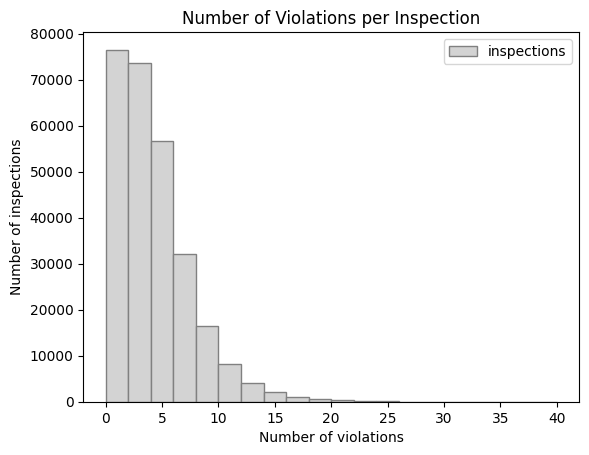

In [ ]:
real['Num_Violations'].plot(kind='hist', bins=20, color='lightgray', edgecolor='grey', label='inspections')
plt.title('Number of Violations per Inspection')
plt.xlabel('Number of violations')
plt.ylabel('Number of inspections')
plt.legend()
plt.show()

In [ ]:
real[real['Num_Violations'] > 30].groupby('Period')['Num_Violations'].count()

Period
Post          6
Transition    2
Name: Num_Violations, dtype: int64

In [ ]:
real[real['Num_Violations'] > 15].groupby('Period')['Num_Violations'].count()

Period
Post          1686
Pre            106
Transition     561
Name: Num_Violations, dtype: int64

In [ ]:
real[real['Period'] == 'Pre']['Num_Violations'].max()

np.int64(23)

In [ ]:
real['Num_Violations'].max()

np.int64(40)

In [ ]:
real[(real['Num_Violations'] == 23) & (real['Period'] == 'Pre')]

,Inspection ID,DBA Name,AKA Name,License #,Facility Type,Risk,Address,City,State,Zip,Inspection Date,Inspection Type,Results,Violations,Latitude,Longitude,Location,Year,Period,Num_Violations
236252,1115232,RACINE BAKERY INC,RACINE BAKERY INC,15456.0,Bakery,Risk 1 (High),6216 S ARCHER AVE,CHICAGO,IL,60638.0,2014-03-27,Complaint,Pass w/ Conditions,"6. HANDS WASHED AND CLEANED, GOOD HYGIENIC PRA...",41.793838,-87.775305,"(41.79383817679765, -87.77530511023124)",2014,Pre,23


In [ ]:
real[(real['Num_Violations'] >= 20) & (real['Num_Violations'] <= 30)].groupby('Results')['Num_Violations'].count()

Results
Fail                  521
Pass                    3
Pass w/ Conditions     88
Name: Num_Violations, dtype: int64

In [ ]:
real[(real['Num_Violations'] >= 20) & (real['Num_Violations'] <= 30)].groupby('Period')['Num_Violations'].count()

Period
Post          434
Pre             8
Transition    170
Name: Num_Violations, dtype: int64

In [ ]:
# average number of violations for each result
real.groupby('Results')['Num_Violations'].mean()

Results
Fail                  6.252550
Pass                  2.392326
Pass w/ Conditions    5.260228
Name: Num_Violations, dtype: float64

In [134]:
after = real[real['Inspection Date'] >= '2018-07-01']['Violations'].dropna()
titles = []
for text in after:
    for v in text.split(' | '):
        violation = v.split(' - Comments')[0]
        if violation[0] == '"':
            titles.append(violation.split('"')[1])
        else:
            titles.append(violation)

violations = sorted(pd.Series(titles).unique())
df = pd.DataFrame({'Violations': violations})
df.to_csv('violations_titles_after.csv', index=False)
df.head()

,Violations
0,"1. PERSON IN CHARGE PRESENT, DEMONSTRATES KNOW..."
1,10. ADEQUATE HANDWASHING SINKS PROPERLY SUPPLI...
2,11. FOOD OBTAINED FROM APPROVED SOURCE
3,12. FOOD RECEIVED AT PROPER TEMPERATURE
4,"13. FOOD IN GOOD CONDITION, SAFE, & UNADULTERATED"


In [125]:
after = real[real['Inspection Date'] >= '2018-07-01']['Violations'].dropna()
titles = []
for text in after:
    for v in text.split(' | '):
        violation = v.split(' - Comments')[0]
        if violation[0] == '"':
            titles.append(violation.split('"')[1])
        else:
            titles.append(violation)

v_nums = []
for v in pd.Series(titles).unique():
    v_nums.append(int(v.split('.')[0]))

max(v_nums)

64

In [135]:
before = real[real['Inspection Date'] < '2018-07-01']['Violations'].dropna()
titles = []
for text in before:
    for v in text.split(' | '):
        violation = v.split(' - Comments')[0]
        if violation[0] == '"':
            titles.append(violation.split('"')[1])
        else:
            titles.append(violation)

v_nums = []
for v in pd.Series(titles).unique():
    v_nums.append(int(v.split('.')[0]))

sorted(v_nums)

[1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36,
 37,
 38,
 39,
 40,
 41,
 42,
 43,
 44,
 45,
 70]

In [136]:
before = real[real['Inspection Date'] < '2018-07-01']['Violations'].dropna()
titles = []
for text in before:
    for v in text.split(' | '):
        violation = v.split(' - Comments')[0]
        if violation[0] == '"':
            titles.append(violation.split('"')[1])
        else:
            titles.append(violation)

violations = sorted(pd.Series(titles).unique())
df2 = pd.DataFrame({'Violations': violations})
df2.to_csv('violations_titles_before.csv', index=False)

## 7. Save a smaller working file (2015–2020)

In [ ]:
work = real[(real['Year'] >= 2015) & (real['Year'] <= 2020)]
print(work.shape)
# work.to_csv('/content/drive/MyDrive/food_2015_2020.csv', index=False)

(99821, 20)


## 8. My 5 observations (write them here)
1. inspection ID shouldn't be used in the model training 
2. Results column has 4 other values beside Pass, Fail and Pass w/ Conditions. Out of Business count is more than half those of Pass w/ Conditions. ig if any should be eliminated it should be based on the research question. 
3. both number of inspection per year chart and share per year chart shows that there was sth different in the regulation change period like for the inspection per year the number dropped at 2018 and for share per year the number of pass w/ conditions increased. we can say that the number of pass w/ conditions has became less and kind of more like the earlier years starting from 2022. sth else nice to mention that the number of inspections also dropped at 2020.
4. as for part 6 one of the codes was about before and after i have to go through this part again inshaAllah
5. the higher number of violations per inspection (possible outliers) are mostly at and after the transition period with the 24-40 violations per inspections. for pre transition the highest was 23